## 选择题

1.C | 2.C | 3.C | 4.A | 5.B | 6.A | 7.A | 8.B

## python程序分析
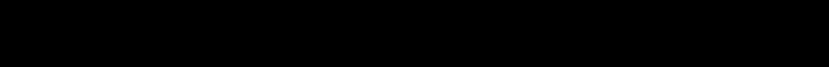

In [ ]:
# 1. 以下程序的功能是对随机产生的 1～100 之间的一个整数 n，利用二分法查找这个数并输出查找的次数。
#  请在横线上填写代码。
import random
import math
n = random.randint(1, 100)  # 函数 random.randint(a,b) 返回从 a 到 b 之间随机选出的一个整数
a, b, cnt = 1, 100, 0
while a<=b:
    cnt += 1
    m = math.ceil((a + b) / 2)  # 函数 math.ceil(x) 的返回值为数值 x 的向上取整
    if n < m:
        b = m - 1
    elif n > m:
        a = m + 1
    else:
        break
print(cnt,n)

In [ ]:
# 2. 以下程序读入正整数 n，计算
#  S = 1! − 2! + 3! − 4! + 5! − …… ± n!
#  并输出。请在横线上填写代码。
n = int(input())
S = 0
sign = 1
k = 1
for i in range(1,n+1):
    k = k*i
    S += sign * k
    sign = -sign
print(S)

In [ ]:
# 3. 下面程序中的 Change 函数的功能是将十进制数转化 N 进制数（2 <= N <= 16）。
#  输入目标进制和待转换的数，函数返回转换后的目标进制数。
#  请在横线上填写代码并给出程序的输出结果。
def Change(radix, num):
    g = []
    while num != 0:
        r = num % radix
        num = num//radix
        g.append(r)
    ans = ''
    t = ('A', 'B', 'C', 'D', 'E', 'F')
    for x in range(len(g)):
        if g[x] >= 10:
            ans += t[g[x]-10]
        else:
            ans += str(g[x])
    return ans[::-1]
print(Change(16, 12455))
# 程序输出：30A7

In [ ]:
# 4. 给定一个整数的数字列表 L，判断 L 中是否存在相同数字，若存在返回 True，否则返回 False。
 # 请在横线上补全代码。
def identical(L):
    flag = 0
    L.sort()
    for i in range(1,len(L)):
        if L[i]==L[i-1]:
            flag = 1
            break
    if flag:
        return True
    else:
        return False

In [47]:
# 5. 程序填空。一个列表 a 中记录了连续多天的营业额，求其中最长的**连续增长（不含相等）**的子序列的长度。
#  例如 [5, 1, 2, 3, 5, 9, 6, 7, 4, 6, 8] 中最长的连续增长（不含相等）的子序列长度是 5（即 [1, 2, 3, 5, 9] 的长度）。
# a = [5, 1, 2, 3, 5, 9, 6, 7, 4, 6, 8, ......（这里省略一些数据）.....]
a=[5, 1, 2, 3, 5, 9, 6, 7, 4, 6, 8]
maxlen = 1
n = 1
for i in range(1,len(a)):
    if a[i]>a[i-1]:
        n += 1
        if maxlen < n :
            maxlen = n
    else:
        n = 1
print(maxlen)

5


## Python数据分析

In [ ]:
# 描述（Description）
# 你获得了一组包含出租车司机及其乘车信息的数据集。
#  你的任务是对这些数据进行一些基本分析，并将结果保存到一个 CSV 文件中。数据包含在以下 CSV 文件中：
# drivers.csv
# driver_id（类型：int）：司机唯一标识符
# age（类型：int）：司机年龄
# second_language（类型：str）：司机的第二语言。如果司机没有第二语言，值为 "no"
# rating（类型：float）：司机的平均评分
#
# rides_{i}.csv
# 分成 4 个文件（rides_1.csv 到 rides_4.csv）：
# ride_id（类型：int）：唯一的乘车标识符
# driver_id（类型：int）：司机标识符
# passenger_id（类型：int）：乘客标识符
# date（类型：str）：乘车日期
# status（类型：str）：乘车状态，可能的值包括
# ¡"Rejected by the driver"（司机拒绝）
# ¡"Cancelled by the passenger"（乘客取消）
# ¡"Success"（成功）
#
# 你的任务如下：
# 1️⃣ 计算司机的平均评分（Average Driver Rating）
# 从 drivers.csv 文件中计算 rating 列的平均值。
# 将结果保存为：
# ¡insight_type: "average_driver_rating"
# ¡value: 计算出的平均评分
#
# 2️⃣ 计算拥有第二语言的司机比例（Percentage of Drivers with a Second Language）
# 计算拥有第二语言的司机的比例（即 second_language 不为 "no" 的司机占总司机数的百分比）。
# 将结果保存为：
# ¡insight_type: "percentage_drivers_with_second_language"
# ¡value: 计算出的百分比
#
# 3️⃣ 计算乘车成功率（Ride Success Rate）
# 将所有 rides_{i}.csv 文件（从 1 到 4）合并为一个整体数据集。
# 计算成功乘车（即 status == "Success"）的比例。
# 将结果保存为：
# ¡insight_type: "ride_success_rate"
# ¡value: 计算出的百分比
#
# 输出要求（Output Requirements）
# 将结果保存到一个名为 analysis_results.csv 的 CSV 文件中 （用代码保存）。
# 该 CSV 文件应包含两列：
# ¡insight_type
# ¡value
# 每一行对应一个任务结果，insight_type 为任务名称，value 为计算结果。
# 所有数值在保留两位小数的范围内视为正确。

In [49]:
import pandas as pd
import numpy as np

In [113]:
# 读取数据
driver_df = pd.read_csv('driver.csv',keep_default_na=False)

rides_dfs = []
for i in range(1, 5):  # 读取 rides_1.csv 到 rides_4.csv
    df = pd.read_csv(f'rides_{i}.csv')
    rides_dfs.append(df)

rides_df = pd.concat(rides_dfs, ignore_index=True)

In [114]:
# 1.计算司机的平均评分（Average Driver Rating）
# 从 drivers.csv 文件中计算 rating 列的平均值。
# 将结果保存为：
# insight_type: "average_driver_rating"
# value: 计算出的平均评分
value = round(driver_df['rating'].mean(),2)
df1 = pd.DataFrame(({'insight_type': ['average_driver_rating'],'value': [value]}))
df1

,insight_type,value
0,average_driver_rating,4.53


In [115]:
# 2.计算拥有第二语言的司机比例（Percentage of Drivers with a Second Language）
# 计算拥有第二语言的司机的比例（即 second_language 不为 "no" 的司机占总司机数的百分比）。
# 将结果保存为：
# insight_type: "percentage_drivers_with_second_language"
# value: 计算出的百分比
value = round(len(driver_df[driver_df['second_language'] != 'None'])/len(driver_df['second_language'])*100, 2)
df2 = pd.DataFrame(({'insight_type': ["percentage_drivers_with_second_language"],'value': [f'{value}%']}))
df2

,insight_type,value
0,percentage_drivers_with_second_language,82.5%


In [116]:
# 3.计算乘车成功率（Ride Success Rate）
# 将所有 rides_{i}.csv 文件（从 1 到 4）合并为一个整体数据集。
# 计算成功乘车（即 status == "Success"）的比例。
# 将结果保存为：
# insight_type: "ride_success_rate"
# value: 计算出的百分比
value = round(len(rides_df[rides_df['status'] == '成功'])/len(rides_df['status'])*100, 2)
df3 = pd.DataFrame(({'insight_type': ["ride_success_rate"],'value': [f'{value}%']}))
df3

,insight_type,value
0,ride_success_rate,65.7%


In [119]:
# 输出要求（Output Requirements）
# 将结果保存到一个名为 analysis_results.csv 的 CSV 文件中 （用代码保存）。
# 该 CSV 文件应包含两列：
# insight_type
# value
# 每一行对应一个任务结果，insight_type 为任务名称，value 为计算结果。
# 所有数值在保留两位小数的范围内视为正确。
result=pd.concat([df1,df2,df3])
result.to_csv('./analysis_results.csv')

## python深度学习

In [ ]:
# 深度学习训练相关名词解释
# 1.简述 Batch Normalization 的基本原理与作用。
# 答：批量归一化是把数据处理为均值为0，方差为1的分布范围，其作用是防止梯度爆炸和梯度消失
# 2.什么是 Dropout？它在深度神经网络训练中的作用是什么？
# 答：Dropout层是随机禁用/丢弃一些神经元，它在深度神经网络训练中的作用是防止过拟合
# 3.解释梯度裁剪的概念及其在训练过程中的作用。
# 答：梯度裁剪是当梯度超过一定阈值时将其重新映射到范围内，它在训练中的作用是保持梯度稳定防止梯度爆炸或梯度消失
# 4.什么是早停？为什么它能防止过拟合？
# 答：当在规定轮次内模型在验证集的性能(如准确率)不再提升时停止训练的技术。因为这时再继续训练只会提升训练集性能。
# 5.数据增强（Data Augmentation）在训练过程中的意义是什么？请举例说明。
# 答：提升数据质量，在数据不足的情况下补充数据，提高模型泛化能力。
# 6.什么是梯度消失？ 为什么会出现？ 有哪些解决办法？
# 答：在反向传播中导数为0叫梯度消失。因为随着网络深度增加，小数会趋于0。解决办法：1.使用正确的初始化和激活函数；2.改善神经网络结构；如使用残差神经网络
# 7.什么是学习率调度？有什么好处？
# 答：学习率调度是在训练过程中根据训练情况和性能变化调整学习率的技术，它可以加快损失函数收敛速度。

In [121]:
# 深度学习预测序列
# 假设我们用 60 天的价格预测第 61 天价格
time_steps = 60
features = 1
samples = 200

# 构造输入数据 (samples, time_steps, features)
x_train = np.random.rand(samples, time_steps, features)  # 200个 60天股票价格
y_train = np.random.rand(samples, 1)                     # 200个 对应的第61天股票价格
x_test  = np.random.rand(10, time_steps, features)       # 测试数据

In [ ]:
# 构建5层Sequential神经网络预测股票价格，要求包含：
# 2个LSTM层（首层units=4需设置input_shape）
# 每个LSTM层后接Dropout层(rate=0.2)
# 最终Dense层(units=1) 实现步骤：
# 1.使用stock_model变量构建模型
# 2.编译模型(loss=‘mean_squared_error’, optimizer=‘adam’)
# 3.训练配置(epochs=5, batch_size=16, verbose=0)
# 4.输出模型summary()
# 5.预测x_test并输出最后一列
# 注意：x_train, y_train, x_test不用再写代码改动

In [124]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, Dense

stock_model = Sequential()
# 添加第一层LSTM层
stock_model.add(LSTM(units=4, input_shape=(time_steps, features), return_sequences=True))
stock_model.add(Dropout(rate=0.2))
# 添加第二个LSTM层
stock_model.add(LSTM(units=4, return_sequences=False))
stock_model.add(Dropout(rate=0.2))
stock_model.add(Dense(units=1))
# 2.编译模型(loss=‘mean_squared_error’, optimizer=‘adam’)
stock_model.compile(loss='mean_squared_error', optimizer='adam')
# 3.训练配置(epochs=5, batch_size=16, verbose=0)
stock_model.fit(x_train, y_train, epochs=5, batch_size=16, verbose=0)
stock_model.summary()
# 预测x_test并输出结果
predictions = stock_model.predict(x_test)
print(f"预测结果:{predictions[:,-1]}")

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_4 (LSTM)               (None, 60, 4)             96        
                                                                 
 dropout_4 (Dropout)         (None, 60, 4)             0         
                                                                 
 lstm_5 (LSTM)               (None, 4)                 144       
                                                                 
 dropout_5 (Dropout)         (None, 4)                 0         
                                                                 
 dense_2 (Dense)             (None, 1)                 5         
                                                                 
Total params: 245 (980.00 Byte)
Trainable params: 245 (980.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
1/1 [===========